# 4 · Conditioned NES: task-space targets and families of metrics

Because NES is a neural network, its inputs can be changed freely.  Two variants (C-NES)
are useful in robotics:

1. **Targets in task space.**  Often we know where the end-effector should go, not which
   joint angles to reach.  C-NES takes the end-effector target $x_s$ as input and finds,
   on its own, the inverse-kinematics solution that is cheapest to reach.
2. **A family of metrics in one network.**  If the metric depends on a parameter $\omega$
   (here the total energy $H$ of the Jacobi metric), $\omega$ becomes an extra input and one
   network represents all the corresponding distance fields.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80

from geodf import metrics, rfm, nes, plotting as P
from geodf.robots import PlanarArm

torch.manual_seed(0)
pi = np.pi
arm = PlanarArm()
lo, hi = [-pi, -pi], [pi, pi]
RETRAIN = False

## 1. Task-space targets: distance to an inverse-kinematics set

Given an end-effector target $x_s$, the set of joint configurations that reach it,
$\{q: f(q)=x_s\}$ ($f$ = forward kinematics), usually has several elements — for our arm two:
elbow up and elbow down.  C-NES learns the distance from any $q_e$ to this whole set:

$$U_\theta(x_s,q_e)=\big\|f(q_e)-x_s\big\|\;\sigma\big(u_\theta(x_s,q_e)\big).$$

The factor $\|f(q_e)-x_s\|$ makes $U$ vanish exactly when the end-effector is at the target,
so the boundary condition is built in **without ever computing the IK solutions**.  The
training loss is the same eikonal loss as before, with targets $x_s=f(q')$ of random
configurations $q'$.  (The joint angles enter the MLP as $\sin q,\cos q$, so the field is
periodic in the joints.)

We use the kinetic-energy metric and the target $x_s=(2,2)$, whose two IK solutions are
$(0,\pi/2)$ and $(\pi/2,-\pi/2)$ — the network is never told these.

In [2]:
G_ke = metrics.kinetic_energy(arm)
reach = arm.l1 + arm.l2
task_model = nes.TaskNES(arm.fk, [-reach, -reach], [reach, reach], lo, hi, hidden=(128, 128, 128))


def task_batch(B=1024):
    q_target = (torch.rand(B, 2) * 2 - 1) * pi             # random reachable targets
    q_e = (torch.rand(B, 2) * 2 - 1) * pi
    return arm.fk(q_target), q_e, None


nes.train_or_load(task_model, "checkpoints/cnes_task_ke.pt", lambda: nes.train(
    task_model, task_batch, lambda q, w: torch.linalg.inv(G_ke(q)), steps=15000, log_every=3000),
    retrain=RETRAIN)
task_model.eval()

loaded checkpoints/cnes_task_ke.pt (trained in 88s)


TaskNES(
  (mlp): MLP(
    (net): Sequential(
      (0): Linear(in_features=6, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
      (4): Linear(in_features=128, out_features=128, bias=True)
      (5): Tanh()
      (6): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)

analytic IK solutions (for reference only):
 [[ 0.     1.571]
 [ 1.571 -1.571]]


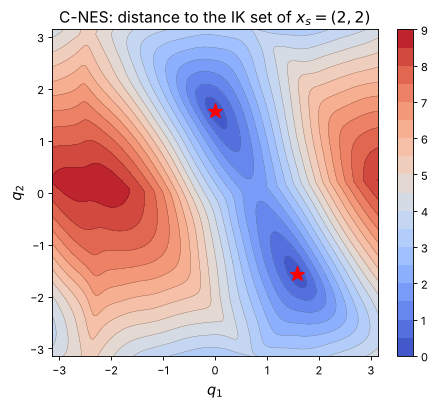

In [3]:
xs = torch.tensor([2.0, 2.0])
n = 150
g1 = np.linspace(-pi, pi, n)
X, Y = np.meshgrid(g1, g1, indexing="ij")
Q = torch.as_tensor(np.stack([X.ravel(), Y.ravel()], -1), dtype=torch.float32)
U, V = nes.geodesic_flow(task_model, xs.expand_as(Q), Q, G_ke, normalize=False)
U, V = U.numpy().reshape(n, n), V.numpy().reshape(n, n, 2)
ik = arm.ik((2.0, 2.0))
print("analytic IK solutions (for reference only):\n", ik.round(3))

fig, ax = plt.subplots(figsize=(6, 5.3))
cf = P.field(ax, X, Y, U)
fig.colorbar(cf, ax=ax, fraction=0.046)
ax.plot(*ik.T, "r*", ms=14)
P.setup_ax(ax, title="C-NES: distance to the IK set of $x_s=(2,2)$")
plt.show()

The learned field has two valleys, exactly at the two IK solutions (red stars, drawn only for
reference).  Following the geodesic flow from any configuration therefore ends at one of them —
the one that is closest *in the metric*, which is not necessarily the closest in joint space.

tab:blue    start [-1.5  1. ]  ->  final q [-0.01  1.58]   end-effector error 0.019
tab:green   start [-2.   2.5]  ->  final q [-0.01  1.58]   end-effector error 0.017
tab:purple  start [2.4 1. ]  ->  final q [0.01 1.56]   end-effector error 0.015
tab:orange  start [ 2.  -2.6]  ->  final q [ 1.58 -1.58]   end-effector error 0.017


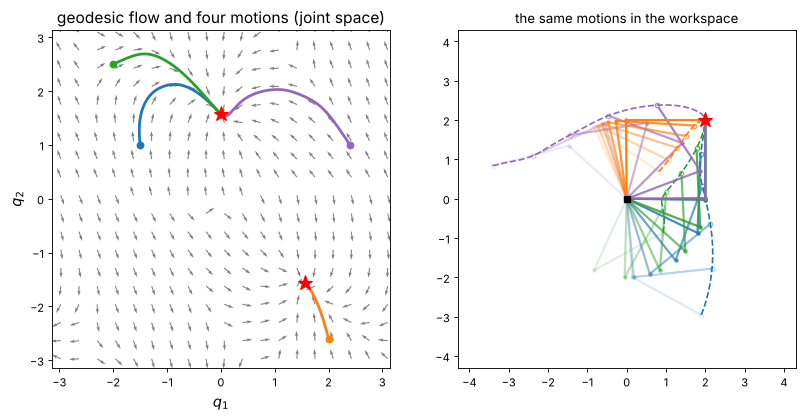

In [4]:
starts = torch.tensor([[-1.5, 1.0], [-2.0, 2.5], [2.4, 1.0], [2.0, -2.6]])
goal_fn = lambda q: torch.linalg.norm(arm.fk(q) - xs, dim=-1)
paths = nes.backtrack(task_model, xs.expand(len(starts), 2), starts, G_ke, step=0.01, tol=0.02, goal_fn=goal_fn)
colors = ["tab:blue", "tab:green", "tab:purple", "tab:orange"]
for s, p, c in zip(starts, paths, colors):
    print(f"{c:11s} start {s.numpy()}  ->  final q {np.round(p[-1], 2)}   "
          f"end-effector error {goal_fn(torch.as_tensor(p[-1:]).float()).item():.3f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
P.quiver(axs[0], X, Y, -V, sub=8, color="gray")
for p, c in zip(paths, colors):
    P.plot_wrapped(axs[0], p, color=c, lw=2.5)
    axs[0].plot(*p[0], "o", color=c)
axs[0].plot(*ik.T, "r*", ms=14)
P.setup_ax(axs[0], title="geodesic flow and four motions (joint space)")
for p, c in zip(paths, colors):
    P.arm_motion(axs[1], arm, p, c, n=6)
axs[1].plot(*xs, "r*", ms=14)
axs[1].set_title("the same motions in the workspace")
plt.show()

All four motions bring the end-effector to $(2,2)$.  Three of them end in the IK solution
$(0,\pi/2)$, the orange one in $(\pi/2,-\pi/2)$ — for each start, the one that is cheaper to
reach under the kinetic-energy metric.  No IK solver was called: the inverse-kinematics
choice comes out of the distance field.

## 2. A family of metrics: the Jacobi metric for every energy level

A robot under gravity that moves freely (no torques) conserves its total energy $H=T+P$.  By
Maupertuis' principle, the paths of these free motions with energy $H$ are exactly the
geodesics of the **Jacobi metric**

$$G(q;H)=2\big(H-P(q)\big)\,M(q),\qquad H>\max_q P(q),$$

and the length of a path is Maupertuis' action $\int p^\top dq$.

$H-P(q)$ is the kinetic energy left at configuration $q$.  The metric is *conformal* to the
kinetic-energy metric (same ellipse shapes, scaled by $2(H-P)$): it is small where the potential
is high (arm pointing up) and large where the arm hangs down.  As $H\to\infty$ the factor becomes
almost constant and the geodesics approach those of $M$.  (Like a thrown ball, whose parabola
bulges *upwards* above the straight chord, the geodesics bend towards high-potential regions,
where the factor $2(H-P)$ is small.)

Instead of one network per energy, C-NES takes $H$ (normalised by $P_{max}$) as an extra input:
$U_\theta(q_s,q_e\,|\,H)$.  During training every pair gets a random $H\in[1.1,2.2]\,P_{max}$.

In [5]:
Pm = arm.P_max
G_H = metrics.jacobi_conditioned(arm)                    # G(q, H)
G_Hw = lambda q, w: G_H(q, w[:, 0] * Pm)                 # with the normalised energy as input
H_range = (1.1, 2.2)
energy_model = nes.NES(lo, hi, hidden=(128, 128, 128), cond_lo=[H_range[0]], cond_hi=[H_range[1]])
cond = lambda B: torch.empty(B, 1).uniform_(*H_range)
nes.train_or_load(energy_model, "checkpoints/cnes_jacobi_paper.pt", lambda: nes.train(
    energy_model, nes.uniform_pair_sampler(lo, hi, 1024, cond), lambda q, w: torch.linalg.inv(G_Hw(q, w)),
    steps=15000, log_every=3000), retrain=RETRAIN)
energy_model.eval()

loaded checkpoints/cnes_jacobi_paper.pt (trained in 131s)


NES(
  (mlp): MLP(
    (net): Sequential(
      (0): Linear(in_features=5, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=128, bias=True)
      (3): Tanh()
      (4): Linear(in_features=128, out_features=128, bias=True)
      (5): Tanh()
      (6): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)

One network, three energies.  Top: distance fields from $q_s=(-0.5,0.8)$; middle: geodesics
from a lattice of starts; bottom: the metric.

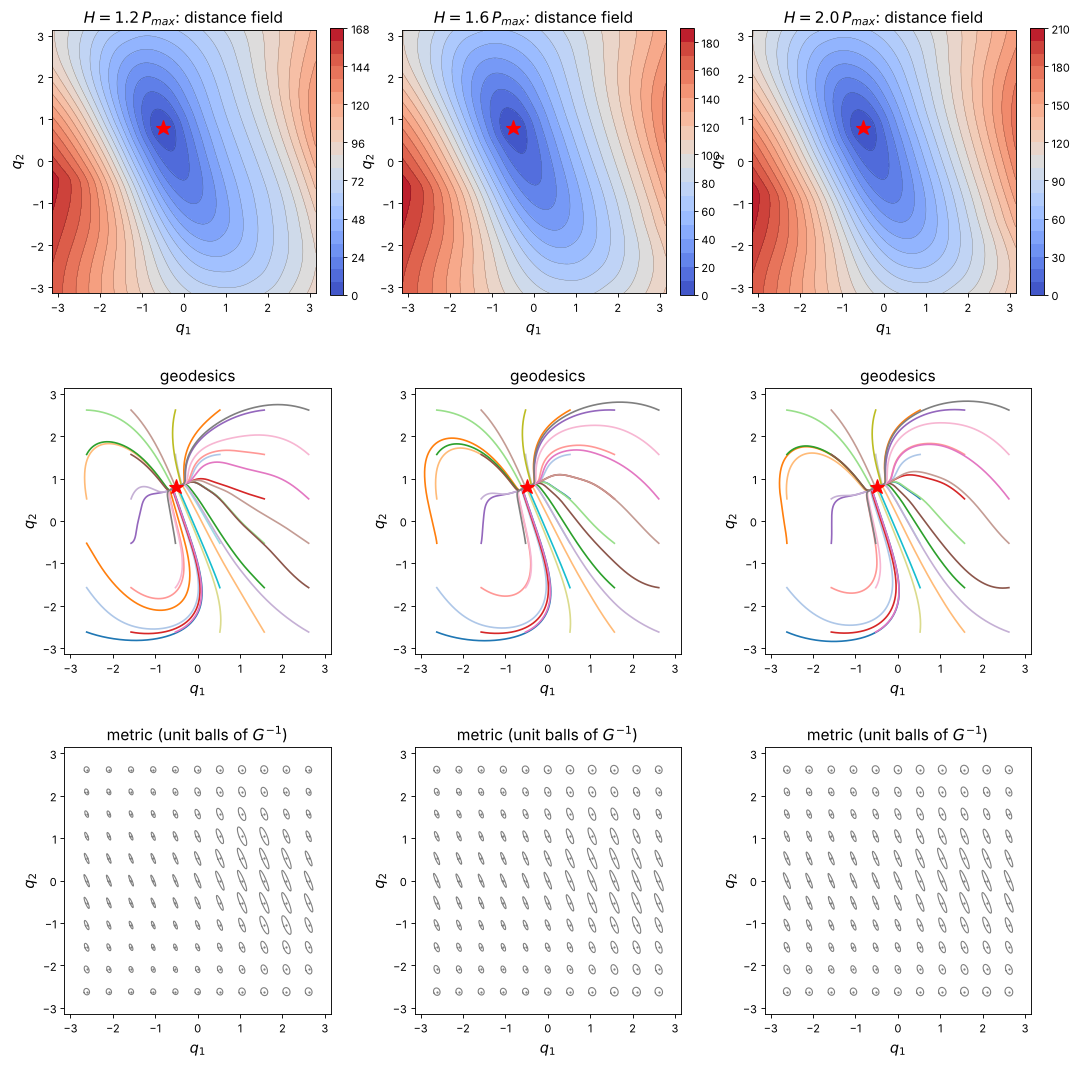

In [6]:
q_s = np.array([-0.5, 0.8])
starts = np.array([[a, b] for a in -5 * pi / 6 + np.arange(6) * pi / 3 for b in -5 * pi / 6 + np.arange(6) * pi / 3])
starts = starts[np.linalg.norm(starts - q_s, axis=1) > 0.3]
src = torch.as_tensor(q_s, dtype=torch.float32)
fig, axs = plt.subplots(3, 3, figsize=(16, 16))
for col, h in enumerate([1.2, 1.6, 2.0]):
    w = torch.full((len(Q), 1), h)
    Uh = energy_model(src.expand_as(Q), Q, w).detach().numpy().reshape(n, n)
    cf = P.field(axs[0, col], X, Y, Uh)
    fig.colorbar(cf, ax=axs[0, col], fraction=0.046)
    axs[0, col].plot(*q_s, "r*", ms=14)
    P.setup_ax(axs[0, col], title=f"$H={h}\\,P_{{max}}$: distance field")
    wb = torch.full((len(starts), 1), h)
    ps = nes.backtrack(energy_model, src.repeat(len(starts), 1), torch.as_tensor(starts, dtype=torch.float32),
                       G_Hw, w=wb, step=0.3, tol=0.03)
    for k, p in enumerate(ps):
        axs[1, col].plot(*p.T, color=plt.get_cmap("tab20")(k % 20), lw=1.5)
    axs[1, col].plot(*q_s, "r*", ms=14)
    P.setup_ax(axs[1, col], title="geodesics")
    P.metric_ellipses(axs[2, col], lambda q, h=h: G_H(q, h * Pm), density=11)
    P.setup_ax(axs[2, col], title="metric (unit balls of $G^{-1}$)")
fig.subplots_adjust(hspace=0.35)
plt.show()

At low energy ($H=1.2P_{max}$) the conformal factor varies by a factor of ~10 over the
workspace: the ellipses are much larger where the arm points up (high potential, little
kinetic energy left) and the geodesics bend to exploit these regions.  At higher energies the
factor is more uniform and the geodesics become closer to the kinetic-energy geodesics of
notebooks 2-3.  Changing $H$ is a single input to the network — no retraining, no new solve.

A sanity check against the grid solver at the three energies:

In [7]:
for h in [1.2, 1.6, 2.0]:
    ref = rfm.solve(lambda q, h=h: G_H(q, h * Pm), ((-pi, pi), (-pi, pi)), 120, q_s)
    Qr = torch.as_tensor(ref.grid.points.reshape(-1, 2), dtype=torch.float32)
    Ur = energy_model(src.expand_as(Qr), Qr, torch.full((len(Qr), 1), h)).detach().numpy().reshape(ref.U.shape)
    print(f"H = {h} P_max:  mean |U_C-NES - U_grid| / mean U = {np.abs(Ur - ref.U).mean() / ref.U.mean() * 100:.1f} %")

H = 1.2 P_max:  mean |U_C-NES - U_grid| / mean U = 4.3 %


H = 1.6 P_max:  mean |U_C-NES - U_grid| / mean U = 4.2 %


H = 2.0 P_max:  mean |U_C-NES - U_grid| / mean U = 4.8 %
